# Experiment 10 — Original vs final tuned BM25F

Compare complete pipelines on the **same 452 queries**, retrieval depth 100 and top-10 researcher ranking. The original uses unstemmed, no-stopword BM25F + CombSUM; tuned uses stemmed/stopword-filtered BM25F + course-discounted CombSUM with document weights (1,3,1). Both use equal field boosts. This is an **in-sample** comparison on the tuning dataset, not independent confirmation.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
root=Path("bm25_final_comparison")
if not root.exists():root=Path("testing/bm25_final_comparison")
summary=pd.read_csv(root/"summary.csv")
metrics=pd.read_csv(root/"metrics.csv")
rankings=pd.read_csv(root/"rankings.csv")
paired=pd.read_csv(root/"paired_differences.csv")
display(summary.round(4))

,configuration,query_type,queries,known_ndcg_at_k,known_mrr_at_k,known_recall_at_k,known_hits_at_k
0,original,overall,452,0.2676,0.2318,0.4197,0.4956
1,original,academic,226,0.3349,0.2931,0.5089,0.6018
2,original,student_style,226,0.2003,0.1705,0.3304,0.3894
3,tuned,overall,452,0.3658,0.3403,0.5056,0.6217
4,tuned,academic,226,0.4131,0.3785,0.5804,0.7080
5,tuned,student_style,226,0.3185,0.3022,0.4308,0.5354


## Overall comparison

configuration,Original BM25,Final tuned BM25
known_ndcg_at_k,0.2676,0.3658
known_mrr_at_k,0.2318,0.3403
known_recall_at_k,0.4197,0.5056


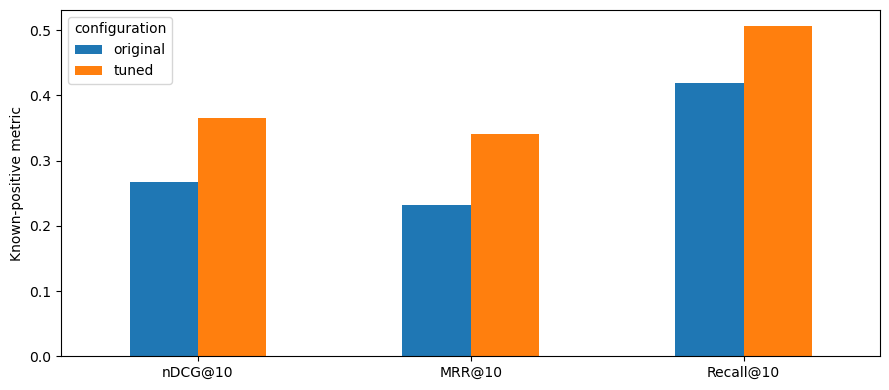

known_ndcg_at_k: 0.2676 -> 0.3658; absolute +0.0982; relative +36.7%
known_mrr_at_k: 0.2318 -> 0.3403; absolute +0.1085; relative +46.8%
known_recall_at_k: 0.4197 -> 0.5056; absolute +0.0860; relative +20.5%


In [2]:
cols=["known_ndcg_at_k","known_mrr_at_k","known_recall_at_k"]
overall=summary.query("query_type == 'overall'").set_index("configuration")
display(overall[cols].T.rename(columns={"original":"Original BM25","tuned":"Final tuned BM25"}).round(4))
ax=overall[cols].T.plot(kind="bar",figsize=(9,4),rot=0)
ax.set_ylabel("Known-positive metric")
ax.set_xticklabels(["nDCG@10","MRR@10","Recall@10"])
plt.tight_layout();plt.show()
for m in cols:
    old,new=overall.loc["original",m],overall.loc["tuned",m]
    print(f"{m}: {old:.4f} -> {new:.4f}; absolute {new-old:+.4f}; relative {(new/old-1)*100:+.1f}%" if old else f"{m}: baseline is zero")

## Academic vs student-style queries

configuration,original,tuned
query_type,,
academic,0.3349,0.4131
student_style,0.2003,0.3185


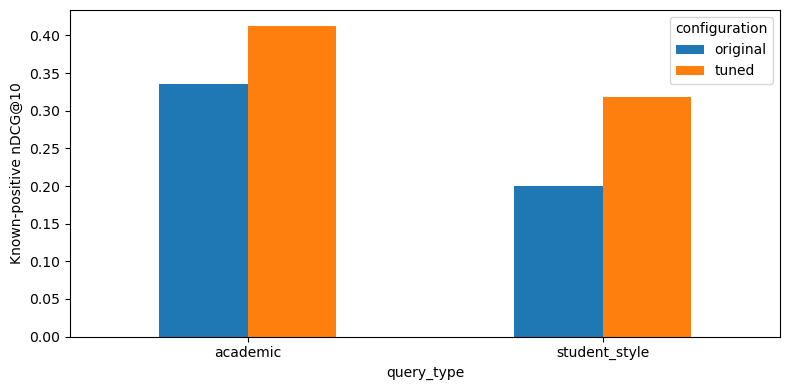

In [3]:
groups=summary[summary.query_type!="overall"]
display(groups.pivot(index="query_type",columns="configuration",values="known_ndcg_at_k").round(4))
ax=groups.pivot(index="query_type",columns="configuration",values="known_ndcg_at_k").plot.bar(rot=0,figsize=(8,4))
ax.set_ylabel("Known-positive nDCG@10");plt.tight_layout();plt.show()

## Paired bootstrap (exploratory)

Bootstrap resamples query rows; source-article clustering and tuning-set reuse are not accounted for. Treat intervals as descriptive.

In [4]:
rng=np.random.default_rng(42)
for m in cols:
    delta=paired[f"delta_{m}"].dropna().to_numpy()
    samples=rng.choice(delta,size=(5000,len(delta)),replace=True).mean(axis=1)
    lo,hi=np.quantile(samples,[.025,.975])
    print(f"{m}: mean Δ={delta.mean():+.4f}; 95% bootstrap interval [{lo:+.4f}, {hi:+.4f}]")

known_ndcg_at_k: mean Δ=+0.0982; 95% bootstrap interval [+0.0737, +0.1240]
known_mrr_at_k: mean Δ=+0.1085; 95% bootstrap interval [+0.0816, +0.1372]
known_recall_at_k: mean Δ=+0.0860; 95% bootstrap interval [+0.0479, +0.1240]


## Top-10 overlap and query-level changes

In [5]:
a=rankings[rankings.configuration=="original"].groupby("query_id").researcher_uuid.apply(set)
b=rankings[rankings.configuration=="tuned"].groupby("query_id").researcher_uuid.apply(set)
overlap=pd.Series({q:len(a[q]&b[q]) for q in a.index.intersection(b.index)})
print("Average top-10 overlap:",round(overlap.mean(),2),"/ 10")
ndcg=paired[["query_id","query","query_type","delta_known_ndcg_at_k"]].sort_values("delta_known_ndcg_at_k",ascending=False)
print("Most improved queries:");display(ndcg.head(10))
print("Most worsened queries:");display(ndcg.tail(10))

Average top-10 overlap: 4.52 / 10
Most improved queries:


,query_id,query,query_type,delta_known_ndcg_at_k
22,23,payment system resilience,academic,1.0
292,293,Training program and european commission,academic,1.0
146,147,Financial times and big things,academic,1.0
135,136,How could I use or study just streets in a uni...,student_style,1.0
181,182,How could I use or study center climate in a u...,student_style,1.0
429,430,How could I use or study politics facebook in ...,student_style,1.0
115,116,How could I use or study nordic baltic in a un...,student_style,1.0
21,22,What would happen if hackers attacked critical...,student_style,1.0
205,206,How could I use or study city planners in a un...,student_style,1.0
279,280,How could I use or study climate initiatives i...,student_style,1.0


Most worsened queries:


,query_id,query,query_type,delta_known_ndcg_at_k
48,49,evolutionary algorithms and AI,academic,-0.369070
257,258,How could I use or study neural networks in a ...,student_style,-0.369070
171,172,How could I use or study neural networks in a ...,student_style,-0.369070
197,198,How could I use or study mega projects in a un...,student_style,-0.386853
185,186,How could I use or study scale projects in a u...,student_style,-0.430677
55,56,Can AI predict what someone will do from brain...,student_style,-0.430677
86,87,Social groups and lecture watch,academic,-0.500000
287,288,How could I use or study data scientists in a ...,student_style,-0.500000
208,209,Brit ross and ross winthereik,academic,-1.000000
322,323,Want change and used real,academic,-1.000000


### Experiment 10: Final Comparison of Original and Optimized BM25F

A final comparative evaluation was conducted to assess the combined effect of the selected BM25F optimization strategies. The original configuration used standard tokenization without stemming or stopword removal, equal field weights, and CombSUM aggregation. The optimized configuration incorporated stemming, stopword removal, Discounted CombSUM aggregation, and document-type weights of 1 for papers, 3 for projects, and 1 for courses.

Both configurations were evaluated using the same 452 queries, a retrieval depth of 100 documents, and researcher rankings truncated at 10 results.

The optimized system achieved an nDCG@10 of 0.3658, compared with 0.2676 for the original configuration, representing a relative improvement of 36.7%. MRR@10 increased from 0.2318 to 0.3403 (+46.8%), while known-positive Recall@10 increased from 0.4197 to 0.5056 (+20.5%).

Improvements were observed for both academic and student-style queries. Academic nDCG@10 increased from 0.3349 to 0.4131 (+23.4%), while student-style nDCG@10 increased from 0.2003 to 0.3185 (+59.0%). This indicates that the optimization was particularly beneficial for queries expressed in less formal, student-oriented language.

The average top-10 researcher overlap between the two configurations was 4.52, demonstrating that the optimizations substantially altered the retrieved researcher sets rather than merely adjusting their ranking positions.

Paired bootstrap analysis yielded an absolute nDCG@10 improvement of 0.0982, with a 95% bootstrap interval of [0.0737, 0.1240]. Similar positive intervals were observed for MRR@10 and Recall@10.

Although the results demonstrate substantial improvements on the evaluation collection, they should not be interpreted as independent evidence of generalization. The final configuration was selected using the same query collection, relevance judgments were incomplete, and some queries were derived from related source material.

Overall, the results support the selected optimized BM25F configuration as the provisional lexical retrieval baseline for subsequent comparisons with embedding-based and hybrid expert search approaches.